In [7]:
# Libraries import code
import ast
import io
import matplotlib.pyplot as plt
import pandas as pd
import requests
import seaborn as sns

# datasets/dataframes to be used
url = "https://1drv.ms/x/c/a2d8e070eb2474a8/IQCs4lZ_juBDS4S53YwSiAPGAYwBr-vaTmPi87dZZQ1yR-U?e=xuOuI5&download=1"
telecom_datos = pd.read_excel(
    io.BytesIO(requests.get(url).content), sheet_name=0
)

In [18]:
df_telco = telecom_datos.copy()
df_telco

,ID_Registro,Fecha,Año,Mes,Estado,Abreviatura,Región,Población_Total,Población_Con_Acceso,Población_Sin_Acceso,Cobertura_%,Suscriptores_Móviles,Suscriptores_Banda_Ancha_Fija,Velocidad_Promedio_Mbps,Latencia_ms,Interrupciones_Servicio,Torres_Celulares,ARPU_USD
0,REG-00001,2025-01-01,2025,Enero,Alabama,AL,Sur,5108047,4373510,734537,0.856200,4590021,1789419,175.9,43.7,11,2147,46.32
1,REG-00002,2025-01-07,2025,Enero,Alabama,AL,Sur,5108539,4384972,723567,0.858361,4860142,2011735,176.8,43.8,10,2148,54.17
2,REG-00003,2025-01-14,2025,Enero,Alabama,AL,Sur,5108922,4411428,697494,0.863475,4416588,2172623,177.8,40.6,14,2142,47.50
3,REG-00004,2025-01-21,2025,Enero,Alabama,AL,Sur,5108749,4395423,713326,0.860372,4667552,1816814,165.5,41.4,15,2126,63.03
4,REG-00005,2025-01-28,2025,Enero,Alabama,AL,Sur,5108951,4406042,702909,0.862416,5063832,2049539,184.1,42.3,11,2135,51.18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3055,REG-03056,2025-12-01,2025,Diciembre,Wyoming,WY,Oeste,585450,500200,85250,0.854386,577438,251250,235.3,34.7,5,358,51.91
3056,REG-03057,2025-12-07,2025,Diciembre,Wyoming,WY,Oeste,585464,503252,82212,0.859578,524218,210812,222.2,38.6,3,354,54.90
3057,REG-03058,2025-12-14,2025,Diciembre,Wyoming,WY,Oeste,585749,500528,85221,0.854509,567634,246695,242.8,38.6,2,356,51.05
3058,REG-03059,2025-12-21,2025,Diciembre,Wyoming,WY,Oeste,585847,503049,82798,0.858670,522306,188986,224.3,37.8,1,355,54.37


In [22]:
df_telco_piv = df_telco.pivot_table(values='ARPU_USD', index='Mes', columns='Región', aggfunc='median')

In [25]:
df_telco_piv

Región,Medio Oeste,Noreste,Oeste,Sur
Mes,,,,
Abril,54.625,54.82,54.45,56.12
Agosto,57.340,52.26,54.80,57.13
Diciembre,55.790,56.34,53.24,55.40
Enero,56.830,53.73,57.35,54.22
Febrero,55.035,56.15,56.30,54.40
Julio,55.645,56.00,55.96,55.43
Junio,55.900,55.41,56.11,54.67
Marzo,55.350,57.05,56.64,54.82
Mayo,54.885,55.40,53.91,56.08


In [ ]:
# Dict to create month matrix
meses_dict = {
    'Enero': 1,
    'Febrero': 2,
    'Marzo': 3,
    'Abril': 4,
    'Mayo': 5,
    'Junio': 6,
    'Julio': 7,
    'Agosto': 8,
    'Septiembre': 9,
    'Octubre': 10,
    'Noviembre': 11,
    'Diciembre': 12,
}

# new column with month #
df_telco_piv['Mes_no'] = (
    df_telco_piv['Mes'].str.strip().str.capitalize().map(meses_dict)
)

df_telco_piv

Región,Mes,Medio Oeste,Noreste,Oeste,Sur,Mes_no
0,Abril,54.625,54.82,54.45,56.12,4
1,Agosto,57.340,52.26,54.80,57.13,8
2,Diciembre,55.790,56.34,53.24,55.40,12
3,Enero,56.830,53.73,57.35,54.22,1
4,Febrero,55.035,56.15,56.30,54.40,2
5,Julio,55.645,56.00,55.96,55.43,7
6,Junio,55.900,55.41,56.11,54.67,6
7,Marzo,55.350,57.05,56.64,54.82,3
8,Mayo,54.885,55.40,53.91,56.08,5
9,Noviembre,55.255,57.21,56.53,55.80,11


In [50]:
# 1. Ordenar ascendentemente por el número de mes
df_telco_piv = df_telco_piv.sort_values(by='Mes_no', ascending=True)

# 2. Eliminar la columna de índice original y la columna auxiliar del número de mes
df_telco_piv = df_telco_piv.drop(columns='Mes_no')

# 3. Reiniciar el índice numérico de la tabla
df_telco_piv = df_telco_piv.reset_index(drop=True)

# Visualizar la tabla limpia
df_telco_piv

Región,Mes,Medio Oeste,Noreste,Oeste,Sur
0,Enero,56.830,53.73,57.35,54.22
1,Febrero,55.035,56.15,56.30,54.40
2,Marzo,55.350,57.05,56.64,54.82
3,Abril,54.625,54.82,54.45,56.12
4,Mayo,54.885,55.40,53.91,56.08
5,Junio,55.900,55.41,56.11,54.67
6,Julio,55.645,56.00,55.96,55.43
7,Agosto,57.340,52.26,54.80,57.13
8,Septiembre,55.025,54.21,57.66,55.30
9,Octubre,54.310,55.86,55.66,55.44


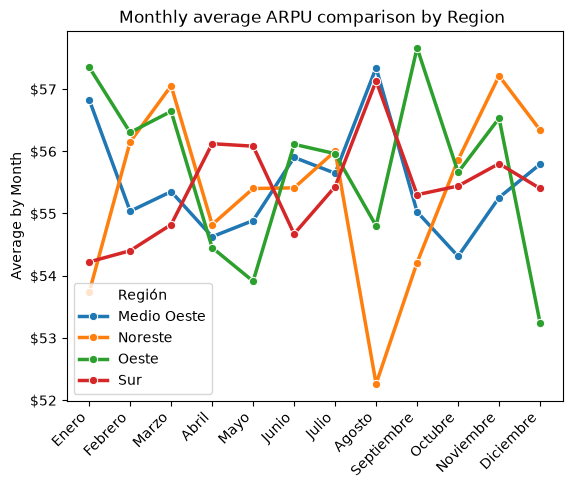

In [72]:
df_melted = df_telco_piv.melt(id_vars=['Mes'], var_name='Región', value_name='Valor')

# Graficar usando df_melted y apuntando y a 'Valor'
sns.lineplot(data=df_melted, x='Mes', y='Valor', hue='Región', marker='o', linewidth=2.5)
plt.title('Monthly average ARPU comparison by Region ')
plt.xlabel('')
plt.ylabel('Average by Month')
plt.xticks(rotation=45, ha='right')
ax=plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'${int(y)}'))
plt.show()
